# Sleep-by-hour → Prism (worked example)

This notebook turns the pipeline's **sleep export** into GraphPad-Prism-ready
spreadsheets. It is a self-contained example — everything runs top to bottom and
the reshaping helpers live in one cell you can copy into your own analysis code.

**Input:** the `sleep_export/` folder written by the *Finalize → Export Sleep Data*
step. We use `sleep_bins_avg.csv` (per-animal metrics averaged across days, one row
per animal × sleep state × 2-hour clock bin).

**Output:** one `.xlsx` with a sheet per *state × metric* (e.g. `w_frac_time`),
laid out as rows = time bins, columns = animals grouped by experimental group —
the shape you paste straight into Prism.

In [1]:
import pandas as pd
from pathlib import Path
from openpyxl import Workbook

## 1. Point at your export and load the by-hour table

In [ ]:
EXPORT_DIR = Path("/Users/leahmcintyre/Data/nri/Stxbp1-vglut2_CKO/sleep_export")

bins = pd.read_csv(EXPORT_DIR / "sleep_bins_avg.csv")
bins.head()

,mouse_id,state,hour_of_day,frac_time,n_bouts,mean_bout_sec,n_days
0,JK1873,n,0,0.262870,21.333333,93.860390,3
1,JK1873,n,2,0.378889,26.000000,115.764754,3
2,JK1873,n,4,0.085833,14.666667,42.051994,3
3,JK1873,n,6,0.494213,22.000000,217.633333,3
4,JK1873,n,8,0.607593,29.000000,161.277541,3


In [6]:
bins['mouse_id'].unique()

<StringArray>
[  'JK1873',   'JK1876',   'JK1928',   'JK1929',   'JK1930',   'JK1931',
   'JK1932',   'JK1935',   'JK1936',   'JK2004',   'JK2007',   'JK2008',
   'JK2010', 'Mice-200', 'Mice-202', 'Mice-203', 'Mice-205', 'Mice-224',
 'Mice-225', 'Mice-226', 'Mice-228', 'Mice-481', 'Mice-482', 'Mice-486',
 'Mice-488', 'Mice-490', 'Mice-491', 'Mice-492', 'Mice-570', 'Mice-572',
 'Mice-573', 'Mice-577', 'Mice-583']
Length: 33, dtype: str

Columns: `mouse_id`, `state` (`w`/`n`/`r`), `hour_of_day` (the 2-hour bin's start
in clock time: 0, 2, … 22, so `6` is 6 AM lights-on and `0` is midnight), the three
metrics `frac_time`, `n_bouts`, `mean_bout_sec`, and `n_days` (how many days were
averaged for that bin).

The export already rotates each recording so it begins at 6 AM, so every animal is
comparable at the same clock hour. In step 4 the writer can convert this clock hour
to **ZT** (hours since lights-on) via `(hour_of_day - anchor) % 24`, where the anchor
hour becomes ZT 0 — 6 AM by default, configurable, or `None` to keep raw clock
hours.

## 2. Assign each animal to a group

Edit the `groups` dict for your project: keys are the group names (they become the
column blocks in Prism), values are the `mouse_id`s exactly as they appear in the
export. The assertion catches any animal you forgot to place.

In [ ]:
groups = {
    'WT': ['JK200', 'JK488', 'JK491', 'JK570', 'JK228', 'JK577']    ``,
    'Flox': ['JK202', 'JK481', 'JK486', 'JK226'],
    'Vglut2-Cre': ['JK1873', 'JK1876', 'JK1928', 'JK1936', 'JK205', 'JK482', 'JK492', 'JK572', 'JK2004', 'JK225', 'JK573'],
    'cHet_Vglut2': ['JK1930', 'JK1931', 'JK1932', 'JK203', 'JK490', 'JK568', 'JK1929', 'JK1935', 'JK2007', 'JK2008','JK2010', 'JK224', 'JK583']
}
bins['mouse_id'] = (bins['mouse_id'].astype('string')
                    .str.replace(r'^Mice-', 'JK', regex=True))

animal_to_group = {a: g for g, animals in groups.items() for a in animals}

bins["group"] = bins["mouse_id"].map(animal_to_group)

unassigned = sorted(bins.loc[bins["group"].isna(), "mouse_id"].unique())
assert not unassigned, f"These animals are not in any group: {unassigned}"
print(f"{len(animal_to_group)} animals assigned across groups: {list(groups)}")

34 animals assigned across groups: ['WT', 'Flox', 'Vglut2-Cre', 'cHet_Vglut2']


## 3. Helpers — reshape to the Prism layout

These functions are the only reusable piece. `write_prism_workbook` optionally
converts each clock hour to ZT (hours since lights-on, set by `zt_anchor_hour`; pass
`None` to keep raw clock hours) and writes one sheet per *state × metric*; each sheet
has two header rows (group name, then animal id) above rows of time bins. **To reuse
this in your own analysis, copy just this cell** into a `.py` module.

In [ ]:
def bin_label(hour: int) -> str:
    """Turn a 2-hour bin start (e.g. 2) into a Prism row label ('2-4')."""
    return f"{int(hour)}-{int(hour) + 2}"


def hour_ampm(hour: int) -> str:
    """Friendly 12-hour label for a clock hour (6 -> '6am', 0 -> '12am')."""
    period = "am" if hour % 24 < 12 else "pm"
    return f"{hour % 12 or 12}{period}"


def write_prism_workbook(
    df,
    out_path,
    *,
    group_order,
    metrics=("frac_time", "n_bouts", "mean_bout_sec"),
    states=("w", "n", "r"),
    clock_col="hour_of_day",
    zt_anchor_hour=6,
):
    """Write one sheet per (state, metric): rows = time bins, columns = animals
    blocked by group, with group-name and animal-id header rows.

    Time handling depends on ``zt_anchor_hour``:
    - an hour (default ``6``): convert clock hours in ``clock_col`` to ZT (hours
      since lights-on) so that hour becomes ZT 0; column labelled ``Time (0 = 6am)``.
    - ``None``: leave the clock hours as-is; column labelled ``Time (clock hour)``.
    """
    sheet_metric = {"n_bouts": "bouts"}  # nicer sheet names; others left as-is
    df = df.copy()
    if zt_anchor_hour is None:
        time_col = clock_col
        time_label = "Time (clock hour)"
    else:
        df["zt"] = (df[clock_col] - zt_anchor_hour) % 24  # clock hour -> ZT hour
        time_col = "zt"
        time_label = f"Time (0 = {hour_ampm(zt_anchor_hour)})"
    time_bins = sorted(df[time_col].unique())

    wb = Workbook()
    wb.remove(wb.active)  # drop the default empty sheet

    for metric in metrics:
        for state in states:
            sub = df[df["state"] == state]
            # animals per group, in the given group order
            group_animals = {
                g: sorted(sub.loc[sub["group"] == g, "mouse_id"].unique())
                for g in group_order
            }
            # pad shorter groups with blank subcolumns so every group block is the
            # same width in Prism (e.g. WT=5, MUT=6 -> WT gets one blank column)
            max_group_size = max((len(a) for a in group_animals.values()), default=0)
            group_animals = {
                g: (a + [None] * (max_group_size - len(a))) if a else a
                for g, a in group_animals.items()
            }
            # wide table for fast (time bin, animal) lookup
            wide = sub.pivot_table(index=time_col, columns="mouse_id", values=metric)

            name = f"{state}_{sheet_metric.get(metric, metric)}"
            ws = wb.create_sheet(name[:31])
            ws.cell(row=2, column=1, value=time_label)

            col = 2
            for g in group_order:
                for animal in group_animals[g]:
                    ws.cell(row=1, column=col, value=g)
                    ws.cell(row=2, column=col, value=animal)
                    col += 1

            for r, b in enumerate(time_bins, start=3):
                ws.cell(row=r, column=1, value=bin_label(b))
                col = 2
                for g in group_order:
                    for animal in group_animals[g]:
                        val = wide.at[b, animal] if animal in wide.columns else None
                        ws.cell(row=r, column=col, value=None if pd.isna(val) else float(val))
                        col += 1

            ws.freeze_panes = "B3"  # keep bin labels + headers visible while scrolling

    wb.save(out_path)
    return out_path

## 4. Write the workbook

In [5]:
# ZT 0 = lights-on. Default 6 (6 AM); set to whatever clock hour your lights
# turn on (e.g. 7 for 7 AM, 19 for 7 PM). Set to None to skip ZT conversion and
# keep the raw clock hours instead.
ZT_ANCHOR_HOUR = 6

OUT_PATH = EXPORT_DIR / "prism_sleep_by_hour.xlsx"
write_prism_workbook(bins, OUT_PATH, group_order=list(groups), zt_anchor_hour=ZT_ANCHOR_HOUR)
print("Wrote", OUT_PATH)

Wrote /media/matt/Data_A/leah/Stxbp1_characterization/sleep_export/prism_sleep_by_hour.xlsx


Each sheet (`w_frac_time`, `w_bouts`, `r_mean_bout_sec`, …) is ready to
copy-paste into a Prism grouped table: the two header rows give the group and
animal, and each column is one animal's values down the time bins.

To adapt this for the **whole-recording** summary instead, load
`sleep_whole_file.csv` and drop the time axis — one row per animal rather than per
bin.

## 5. Plot sleep architecture by group

A 3×3 grid of group means ± SEM per 2-hour bin — rows are `n_bouts` / `mean_bout_sec`
/ `frac_time`, columns are Wake / NREM / REM — the standard sleep-architecture panel
layout. Reuses `groups` and `ZT_ANCHOR_HOUR` from above; the shaded region marks
lights-off (`DARK_ONSET_ZT` through ZT 24).

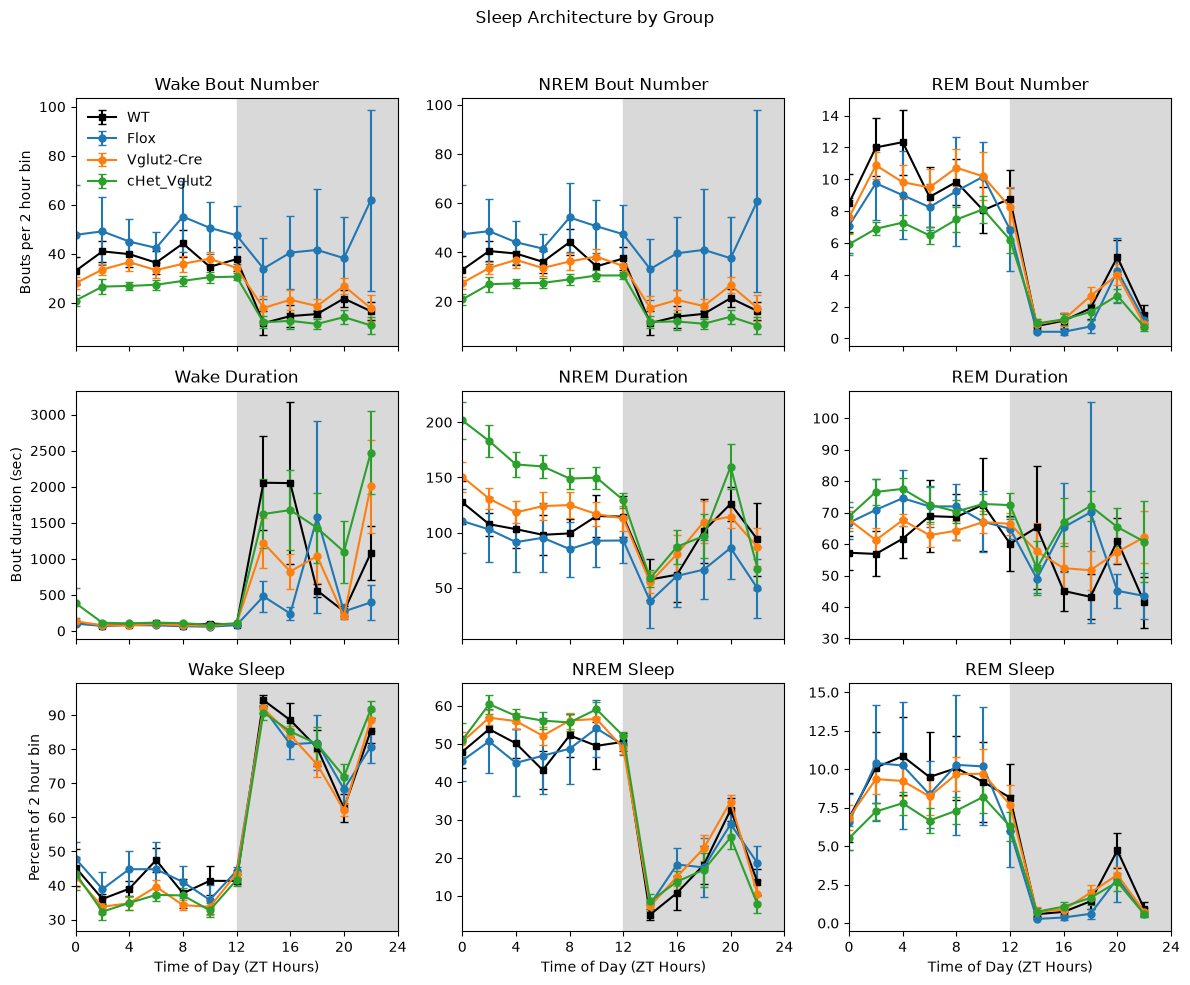

In [10]:
import matplotlib.pyplot as plt

ZT_ANCHOR_HOUR = 6

FIGURE_TITLE = "Sleep Architecture by Group"
DARK_ONSET_ZT = 12  # ZT hour lights turn off; shaded through ZT 24

STATE_ORDER = ["w", "n", "r"]
STATE_LABELS = {"w": "Wake", "n": "NREM", "r": "REM"}
# (column, title, y-axis label, scale factor for display)
METRIC_ROWS = [
    ("n_bouts", "Bout Number", "Bouts per 2 hour bin", 1),
    ("mean_bout_sec", "Duration", "Bout duration (sec)", 1),
    ("frac_time", "Sleep", "Percent of 2 hour bin", 100),
]
GROUP_STYLE = {
    "WT": dict(color="black", marker="s"),
    "MUT": dict(color="red", marker="o"),
}

plot_df = bins.copy()
plot_df["zt"] = (plot_df["hour_of_day"] - ZT_ANCHOR_HOUR) % 24

fig, axes = plt.subplots(len(METRIC_ROWS), len(STATE_ORDER), figsize=(12, 10), sharex=True)
fig.suptitle(FIGURE_TITLE)

for row, (metric, metric_title, ylabel, scale) in enumerate(METRIC_ROWS):
    for col, state in enumerate(STATE_ORDER):
        ax = axes[row, col]
        ax.axvspan(DARK_ONSET_ZT, 24, color="0.85", zorder=0)

        for group in groups:
            sub = plot_df[(plot_df["state"] == state) & (plot_df["group"] == group)]
            agg = sub.groupby("zt")[metric].agg(["mean", "sem"]).sort_index()
            style = GROUP_STYLE.get(group, {})
            ax.errorbar(
                agg.index, agg["mean"] * scale, yerr=agg["sem"] * scale,
                label=group, linestyle="-", capsize=3, markersize=5,
                marker=style.get("marker", "o"), color=style.get("color"),
            )

        ax.set_title(f"{STATE_LABELS[state]} {metric_title}")
        ax.set_xlim(0, 24)
        ax.set_xticks(range(0, 25, 4))
        if col == 0:
            ax.set_ylabel(ylabel)
        if row == len(METRIC_ROWS) - 1:
            ax.set_xlabel("Time of Day (ZT Hours)")

axes[0, 0].legend(loc="upper left", frameon=False)
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()